# Density matrices, decay fits, chi-squared and winding

Run down the notebook in order. Every graph is drawn in its own cell using ordinary NumPy, SciPy and Matplotlib lines. There are no custom helper functions or analysis-module imports.

We use L = 32, 64 and 128 at all nine temperatures. Folder names contain **inverse temperature beta**; every temperature axis below is **T = 1 / beta**. New density measurements are used where available, with the original results at the other points. The simulation files are read only.

In [25]:
from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.stats import chi2

root = Path.cwd()
for folder in (root, *root.parents):
    if (folder / 'results' / 'clean_Rb87').is_dir():
        root = folder
        break
results = root / 'results'

sizes = [32, 64, 128]
betas = [.70, .60, .52, .45, .39, .35, .32, .30, .28]
T = 1 / np.array(betas)
colours = ['tab:green', 'tab:blue', 'tab:orange']
plt.rcParams.update({'figure.figsize': (7, 4.5), 'figure.dpi': 110})

## Read the three production files at each point

Keep the density matrices, their stored standard errors, the histogram counts, and both winding components. The winding plots use these same production files. A printed row shows which folder was used and how many density histograms each production contains.

In [26]:
density_runs, density_error_runs, histograms = {}, {}, {}
winding_runs, winding_error_runs, winding_samples = {}, {}, {}

for L in sizes:
    for beta in betas:
        name = f'l{L}t{round(100 * beta):03d}'
        folder = results / 'cleanRbRDM' / name
        if not folder.is_dir():
            folder = results / 'clean_Rb87' / name
        files = sorted(folder.glob('*prod[0-9][0-9].h5'))
        assert len(files) == 3, f'Expected three productions in {folder}'

        density_runs[L, beta] = np.zeros((3, L, L))
        density_error_runs[L, beta] = np.zeros((3, L, L))
        histograms[L, beta] = np.zeros(3)
        winding_runs[L, beta] = np.zeros((3, 2))
        winding_error_runs[L, beta] = np.zeros((3, 2))
        winding_samples[L, beta] = np.zeros(3)
        for p, file in enumerate(files):
            with h5py.File(file, 'r') as f:
                density = f['simulation/results/Density_Matrix']
                density_runs[L, beta][p] = density['mean/value'][()].reshape(L, L)
                density_error_runs[L, beta][p] = density['mean/error'][()].reshape(L, L)
                histograms[L, beta][p] = density['count'][()]
                winding = f['simulation/results/Winding_number_squared']
                winding_runs[L, beta][p] = winding['mean/value'][()]
                winding_error_runs[L, beta][p] = winding['mean/error'][()]
                winding_samples[L, beta][p] = winding['count'][()]
        print(name, folder.parent.name, histograms[L, beta].astype(int))

l32t070 clean_Rb87 [146 120 120]
l32t060 clean_Rb87 [144 144 144]
l32t052 clean_Rb87 [180 169 180]
l32t045 clean_Rb87 [285 287 287]
l32t039 clean_Rb87 [344 347 347]
l32t035 clean_Rb87 [407 421 420]
l32t032 clean_Rb87 [468 472 470]
l32t030 clean_Rb87 [466 470 471]
l32t028 clean_Rb87 [471 468 470]
l64t070 cleanRbRDM [158 139 132]
l64t060 cleanRbRDM [191 188 189]
l64t052 clean_Rb87 [48 48 48]
l64t045 clean_Rb87 [72 72 72]
l64t039 clean_Rb87 [ 96  96 102]
l64t035 clean_Rb87 [ 98 106 108]
l64t032 clean_Rb87 [187 187 177]
l64t030 clean_Rb87 [281 286 195]
l64t028 clean_Rb87 [469 466 467]
l128t070 cleanRbRDM [33 34 33]
l128t060 cleanRbRDM [48 46 43]
l128t052 cleanRbRDM [61 63 65]
l128t045 cleanRbRDM [92 82 80]
l128t039 cleanRbRDM [119 110 109]
l128t035 cleanRbRDM [166 160 160]
l128t032 clean_Rb87 [41 41 40]
l128t030 clean_Rb87 [ 47  97 103]
l128t028 clean_Rb87 [382 405 447]


## Average the productions

Weight each density matrix by its histogram count. The error below is the propagated standard error, $\sigma^2=\sum_p w_p^2\sigma_p^2$. Winding has its own measurement counts, so use those weights for winding.

**Error assumption:** this propagation neglects covariance between production windows and spatial directions. The later chi-squared also neglects covariance between distances. Its value and nominal p-value are therefore approximate; they are not a calibrated correlated-data test. Error bars below are these standard errors, rather than the spread of three productions. There is no shaded band.

In [27]:
G, G_error, W, W_error = {}, {}, {}, {}
for L in sizes:
    for beta in betas:
        weights = histograms[L, beta] / histograms[L, beta].sum()
        G[L, beta] = np.average(density_runs[L, beta], axis=0, weights=weights)
        G_error[L, beta] = np.sqrt(np.sum(
            (weights[:, None, None] * density_error_runs[L, beta])**2, axis=0))

        weights = winding_samples[L, beta] / winding_samples[L, beta].sum()
        W[L, beta] = np.average(winding_runs[L, beta], axis=0, weights=weights)
        W_error[L, beta] = np.sqrt(np.sum(
            (weights[:, None] * winding_error_runs[L, beta])**2, axis=0))

## Choose a temperature to inspect

Change `beta` here and rerun the three matrix plots. All three use the same colour scale. These are displacement matrices G(dx, dy), with zero separation shifted to the centre.

In [28]:
beta = .35
colour_max = max(G[L, beta].max() for L in sizes)
print(f'beta = {beta}, T = {1 / beta:.4f}')

beta = 0.35, T = 2.8571


### Density matrix: L = 32

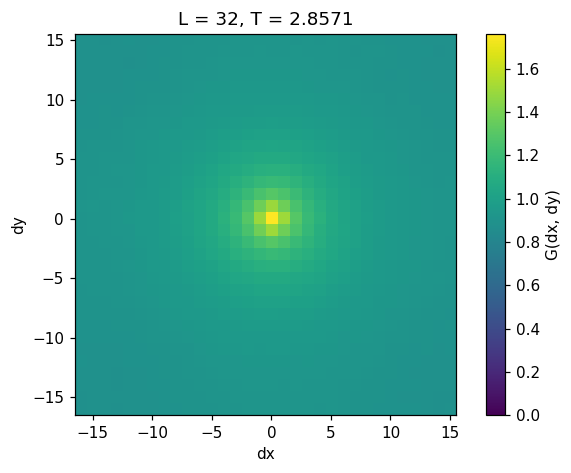

In [29]:
L = 32
plt.figure()
plt.imshow(np.fft.fftshift(G[L, beta]), origin='lower', vmin=0, vmax=colour_max,
           extent=(-L/2-.5, L/2-.5, -L/2-.5, L/2-.5))
plt.colorbar(label='G(dx, dy)')
plt.xlabel('dx')
plt.ylabel('dy')
plt.title(f'L = {L}, T = {1 / beta:.4f}')
plt.show()

### Density matrix: L = 64

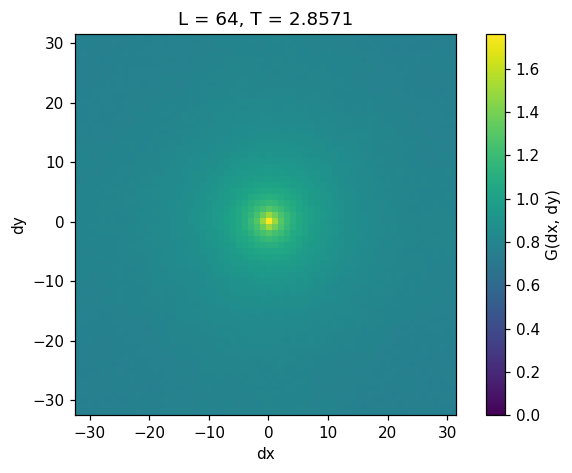

In [30]:
L = 64
plt.figure()
plt.imshow(np.fft.fftshift(G[L, beta]), origin='lower', vmin=0, vmax=colour_max,
           extent=(-L/2-.5, L/2-.5, -L/2-.5, L/2-.5))
plt.colorbar(label='G(dx, dy)')
plt.xlabel('dx')
plt.ylabel('dy')
plt.title(f'L = {L}, T = {1 / beta:.4f}')
plt.show()

### Density matrix: L = 128

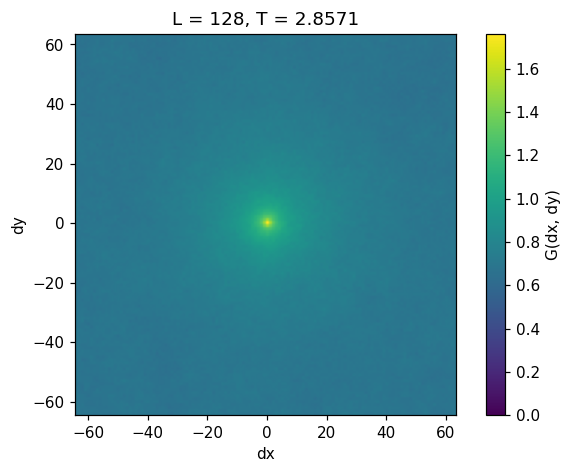

In [31]:
L = 128
plt.figure()
plt.imshow(np.fft.fftshift(G[L, beta]), origin='lower', vmin=0, vmax=colour_max,
           extent=(-L/2-.5, L/2-.5, -L/2-.5, L/2-.5))
plt.colorbar(label='G(dx, dy)')
plt.xlabel('dx')
plt.ylabel('dy')
plt.title(f'L = {L}, T = {1 / beta:.4f}')
plt.show()

## Turn each matrix into G(r)

Average the four axial directions: $G(r)=[G(r,0)+G(-r,0)+G(0,r)+G(0,-r)]/4$. The error is the square root of the sum of their variances, divided by four. Use $1\leq r<L/2$, so these four points are distinct.

In [32]:
distance, profile, profile_error = {}, {}, {}
for L in sizes:
    r = np.arange(1, L // 2)
    distance[L] = r
    for beta in betas:
        matrix = G[L, beta]
        error = G_error[L, beta]
        profile[L, beta] = (matrix[0, r] + matrix[0, -r]
                            + matrix[r, 0] + matrix[-r, 0]) / 4
        profile_error[L, beta] = np.sqrt(error[0, r]**2 + error[0, -r]**2
                                         + error[r, 0]**2 + error[-r, 0]**2) / 4

### Decay at every temperature: L = 32

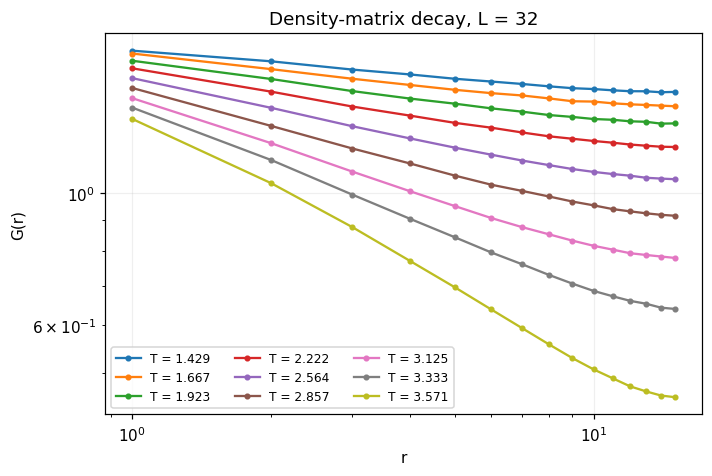

In [33]:
L = 32
plt.figure()
for beta in betas:
    plt.loglog(distance[L], profile[L, beta], 'o-', ms=3, label=f'T = {1 / beta:.3f}')
plt.xlabel('r')
plt.ylabel('G(r)')
plt.title(f'Density-matrix decay, L = {L}')
plt.legend(ncol=3, fontsize=8)
plt.grid(alpha=.2)
plt.show()

### Decay at every temperature: L = 64

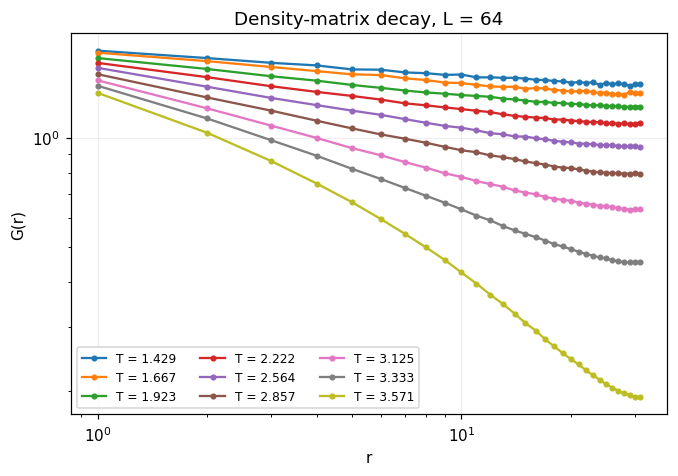

In [34]:
L = 64
plt.figure()
for beta in betas:
    plt.loglog(distance[L], profile[L, beta], 'o-', ms=3, label=f'T = {1 / beta:.3f}')
plt.xlabel('r')
plt.ylabel('G(r)')
plt.title(f'Density-matrix decay, L = {L}')
plt.legend(ncol=3, fontsize=8)
plt.grid(alpha=.2)
plt.show()

### Decay at every temperature: L = 128

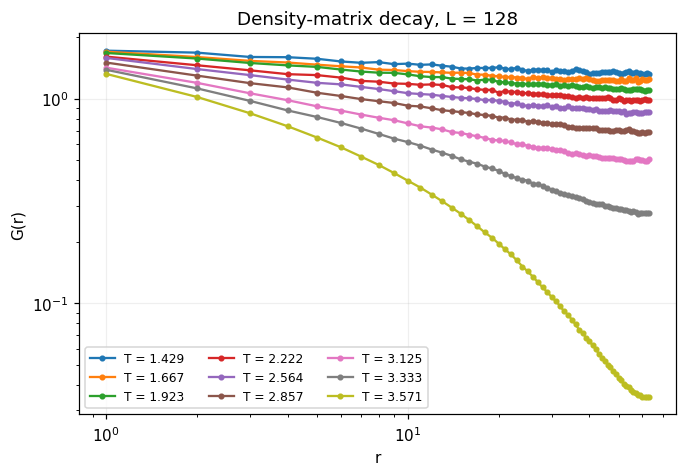

In [35]:
L = 128
plt.figure()
for beta in betas:
    plt.loglog(distance[L], profile[L, beta], 'o-', ms=3, label=f'T = {1 / beta:.3f}')
plt.xlabel('r')
plt.ylabel('G(r)')
plt.title(f'Density-matrix decay, L = {L}')
plt.legend(ncol=3, fontsize=8)
plt.grid(alpha=.2)
plt.show()

### Compare the three sizes at one temperature

Change `beta` to compare another temperature. The curves are not normalized.

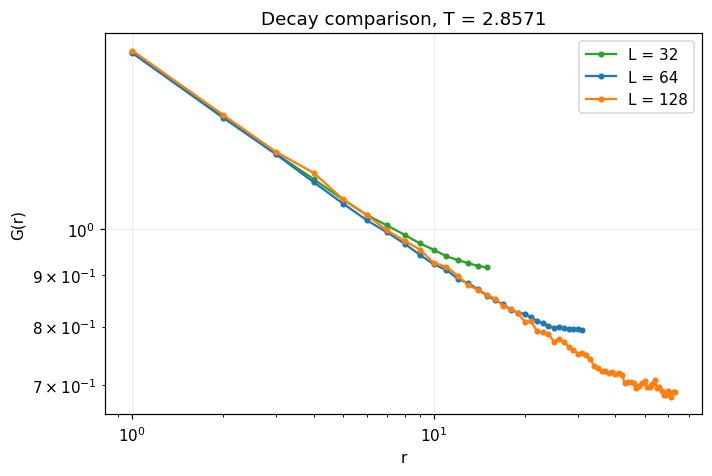

In [36]:
beta = .35
plt.figure()
for L, colour in zip(sizes, colours):
    plt.loglog(distance[L], profile[L, beta], 'o-', ms=3, color=colour, label=f'L = {L}')
plt.xlabel('r')
plt.ylabel('G(r)')
plt.title(f'Decay comparison, T = {1 / beta:.4f}')
plt.legend()
plt.grid(alpha=.2)
plt.show()

## Fit one example, step by step

Choose `L` and `beta`. Both models use exactly the same unnormalized data and errors over $\max(3,L/16)\leq r\leq L/4$. The interval avoids the shortest distances and the strongest periodic-boundary effects. It is a finite fitting window, not a proof of an asymptotic law.

In [37]:
L = 128
beta = .35
r = distance[L]
y = profile[L, beta]
sigma = profile_error[L, beta]
r_min = max(3, L // 16)
r_max = L // 4
use = (r >= r_min) & (r <= r_max)
r_fit = r[use]
y_fit = y[use]
sigma_fit = sigma[use]
print(f'L = {L}, T = {1 / beta:.4f}: r = {r_min} to {r_max}, {len(r_fit)} points')

L = 128, T = 2.8571: r = 8 to 32, 25 points


### Algebraic decay: $G(r)=A r^{-\eta}$

Fit directly to G(r), with two positive parameters. `absolute_sigma=True` keeps the supplied errors fixed; it does not rescale them to make reduced chi-squared equal to one.

A = 1.447465, eta = 0.191924


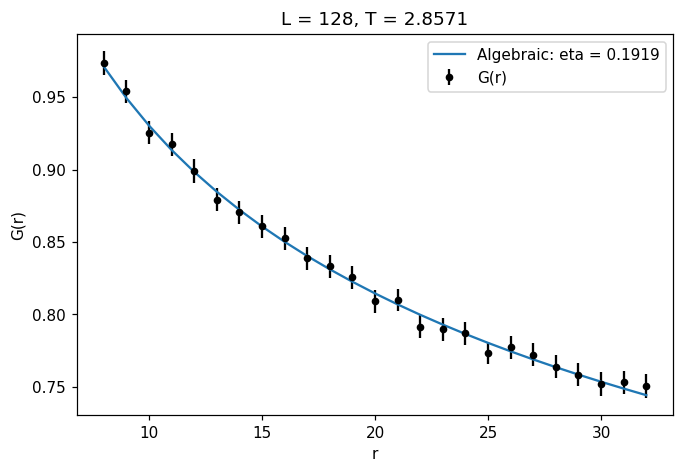

In [38]:
algebraic = lambda r, A, eta: A * r**(-eta)
p_alg, covariance_alg = curve_fit(algebraic, r_fit, y_fit, p0=(2, .2),
                                 sigma=sigma_fit, absolute_sigma=True, bounds=(0, np.inf))
A_alg, eta = p_alg
print(f'A = {A_alg:.6f}, eta = {eta:.6f}')

plt.figure()
plt.errorbar(r_fit, y_fit, yerr=sigma_fit, fmt='ko', ms=4, label='G(r)')
plt.plot(r_fit, algebraic(r_fit, *p_alg), label=f'Algebraic: eta = {eta:.4f}')
plt.xlabel('r')
plt.ylabel('G(r)')
plt.title(f'L = {L}, T = {1 / beta:.4f}')
plt.legend()
plt.show()

### Exponential decay: $G(r)=A\exp(-r/\xi)$

A = 1.023797, xi = 93.203525 lattice spacings


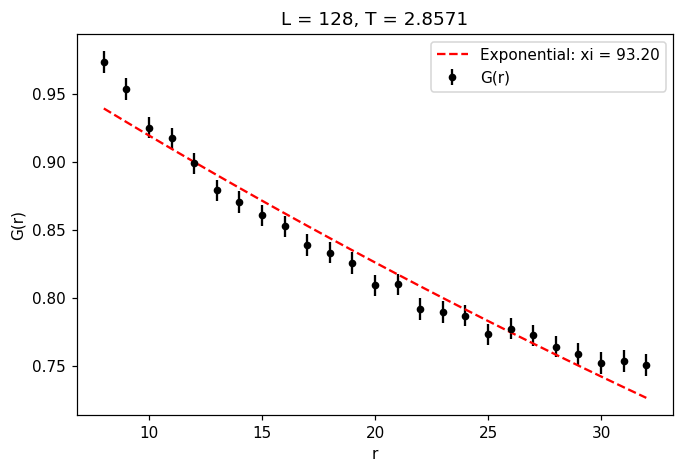

In [39]:
exponential = lambda r, A, xi: A * np.exp(-r / xi)
p_exp, covariance_exp = curve_fit(exponential, r_fit, y_fit, p0=(2, L),
                                 sigma=sigma_fit, absolute_sigma=True, bounds=(0, np.inf))
A_exp, xi = p_exp
print(f'A = {A_exp:.6f}, xi = {xi:.6f} lattice spacings')

plt.figure()
plt.errorbar(r_fit, y_fit, yerr=sigma_fit, fmt='ko', ms=4, label='G(r)')
plt.plot(r_fit, exponential(r_fit, *p_exp), 'r--', label=f'Exponential: xi = {xi:.2f}')
plt.xlabel('r')
plt.ylabel('G(r)')
plt.title(f'L = {L}, T = {1 / beta:.4f}')
plt.legend()
plt.show()

### Calculate chi-squared explicitly

$\chi^2=\sum_i[(G_i-G_{\mathrm{fit},i})/\sigma_i]^2$, degrees of freedom $\nu=N-2$, and reduced chi-squared $\chi^2/\nu$. `chi2.sf` gives the nominal upper-tail probability under independent Gaussian errors. Here the unmeasured correlations make that probability approximate. Lower chi-squared means smaller error-weighted residuals; the two models have the same number of parameters.

In [40]:
chi_alg = np.sum(((y_fit - algebraic(r_fit, *p_alg)) / sigma_fit)**2)
chi_exp = np.sum(((y_fit - exponential(r_fit, *p_exp)) / sigma_fit)**2)
dof = len(r_fit) - 2
reduced_alg = chi_alg / dof
reduced_exp = chi_exp / dof
p_alg_nominal = chi2.sf(chi_alg, dof)
p_exp_nominal = chi2.sf(chi_exp, dof)

print('Degrees of freedom:', dof)
print(f'Algebraic:   chi2 = {chi_alg:.4f}, reduced = {reduced_alg:.4f}, nominal p = {p_alg_nominal:.4g}')
print(f'Exponential: chi2 = {chi_exp:.4f}, reduced = {reduced_exp:.4f}, nominal p = {p_exp_nominal:.4g}')

Degrees of freedom: 23
Algebraic:   chi2 = 5.9354, reduced = 0.2581, nominal p = 0.9999
Exponential: chi2 = 74.4379, reduced = 3.2364, nominal p = 2.464e-07


### Put both fits on the same graph

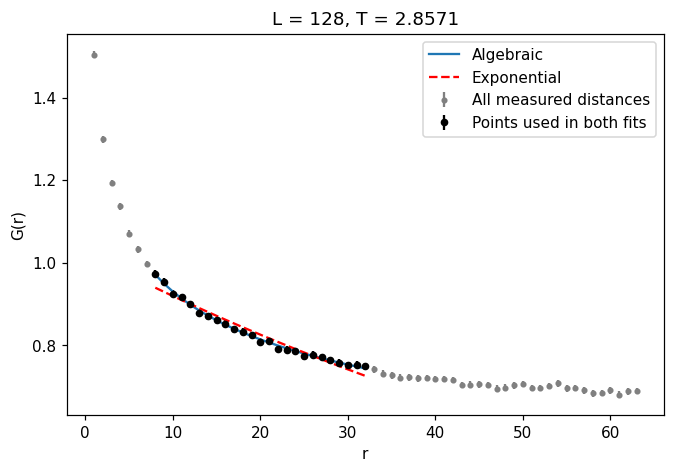

In [41]:
plt.figure()
plt.errorbar(r, y, yerr=sigma, fmt='.', color='grey', label='All measured distances')
plt.errorbar(r_fit, y_fit, yerr=sigma_fit, fmt='ko', ms=4, label='Points used in both fits')
plt.plot(r_fit, algebraic(r_fit, *p_alg), label='Algebraic')
plt.plot(r_fit, exponential(r_fit, *p_exp), 'r--', label='Exponential')
plt.xlabel('r')
plt.ylabel('G(r)')
plt.title(f'L = {L}, T = {1 / beta:.4f}')
plt.legend()
plt.show()

## Repeat those same fits for every size and temperature

The first index in the result arrays selects L32, L64 or L128. The second follows `T`. Parameter columns are (A, eta) for algebraic and (A, xi) for exponential. This loop repeats the calculations above; there is no separate fitting helper.

In [42]:
alg_parameters = np.zeros((3, len(betas), 2))
exp_parameters = np.zeros((3, len(betas), 2))
alg_chi2 = np.zeros((3, len(betas)))
exp_chi2 = np.zeros((3, len(betas)))
degrees_of_freedom = np.zeros((3, len(betas)), dtype=int)

for i, L in enumerate(sizes):
    for j, beta in enumerate(betas):
        r = distance[L]
        use = (r >= max(3, L // 16)) & (r <= L // 4)
        r_fit = r[use]
        y_fit = profile[L, beta][use]
        sigma_fit = profile_error[L, beta][use]
        alg_parameters[i, j], _ = curve_fit(algebraic, r_fit, y_fit, p0=(2, .2),
            sigma=sigma_fit, absolute_sigma=True, bounds=(0, np.inf))
        exp_parameters[i, j], _ = curve_fit(exponential, r_fit, y_fit, p0=(2, L),
            sigma=sigma_fit, absolute_sigma=True, bounds=(0, np.inf))
        alg_chi2[i, j] = np.sum(((y_fit - algebraic(r_fit, *alg_parameters[i, j])) / sigma_fit)**2)
        exp_chi2[i, j] = np.sum(((y_fit - exponential(r_fit, *exp_parameters[i, j])) / sigma_fit)**2)
        degrees_of_freedom[i, j] = len(r_fit) - 2

alg_reduced = alg_chi2 / degrees_of_freedom
exp_reduced = exp_chi2 / degrees_of_freedom
alg_p_nominal = chi2.sf(alg_chi2, degrees_of_freedom)
exp_p_nominal = chi2.sf(exp_chi2, degrees_of_freedom)
print('Finished: 27 points, two models at each point.')

Finished: 27 points, two models at each point.


### Algebraic exponent $\eta$ against temperature

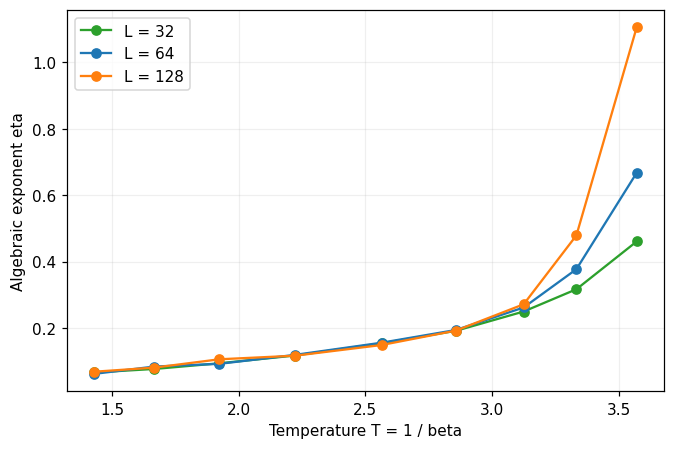

In [43]:
plt.figure()
for i, L in enumerate(sizes):
    plt.plot(T, alg_parameters[i, :, 1], 'o-', color=colours[i], label=f'L = {L}')
plt.xlabel('Temperature T = 1 / beta')
plt.ylabel('Algebraic exponent eta')
plt.legend()
plt.grid(alpha=.2)
plt.show()

### Exponential decay length $\xi$ against temperature

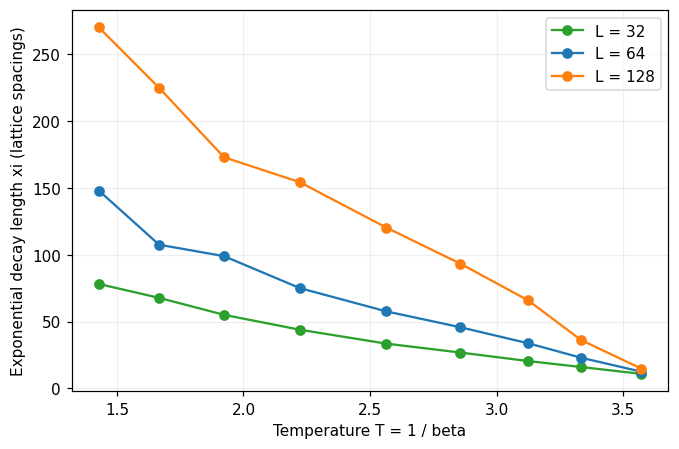

In [44]:
plt.figure()
for i, L in enumerate(sizes):
    plt.plot(T, exp_parameters[i, :, 1], 'o-', color=colours[i], label=f'L = {L}')
plt.xlabel('Temperature T = 1 / beta')
plt.ylabel('Exponential decay length xi (lattice spacings)')
plt.legend()
plt.grid(alpha=.2)
plt.show()

### Algebraic amplitude A against temperature

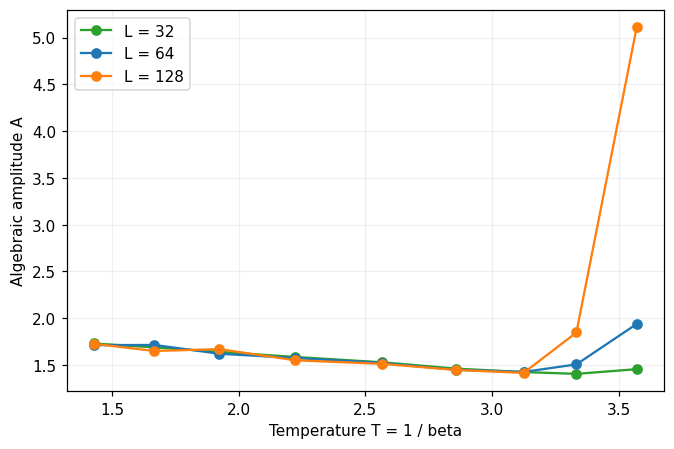

In [45]:
plt.figure()
for i, L in enumerate(sizes):
    plt.plot(T, alg_parameters[i, :, 0], 'o-', color=colours[i], label=f'L = {L}')
plt.xlabel('Temperature T = 1 / beta')
plt.ylabel('Algebraic amplitude A')
plt.legend()
plt.grid(alpha=.2)
plt.show()

### Exponential amplitude A against temperature

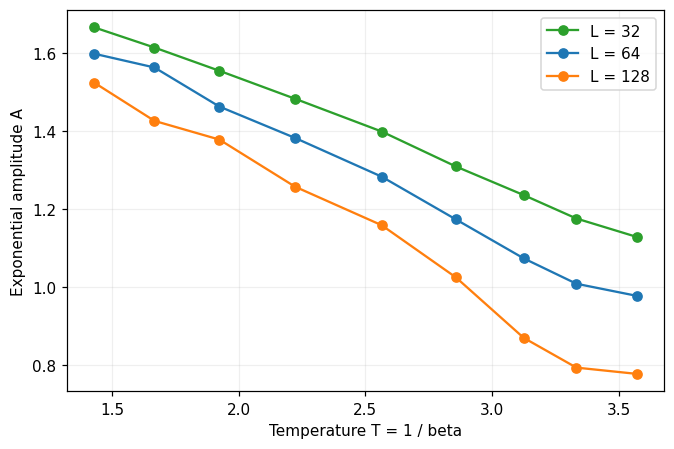

In [46]:
plt.figure()
for i, L in enumerate(sizes):
    plt.plot(T, exp_parameters[i, :, 0], 'o-', color=colours[i], label=f'L = {L}')
plt.xlabel('Temperature T = 1 / beta')
plt.ylabel('Exponential amplitude A')
plt.legend()
plt.grid(alpha=.2)
plt.show()

### Chi-squared (diagonal errors) against temperature

A logarithmic vertical axis keeps the small and large values visible.

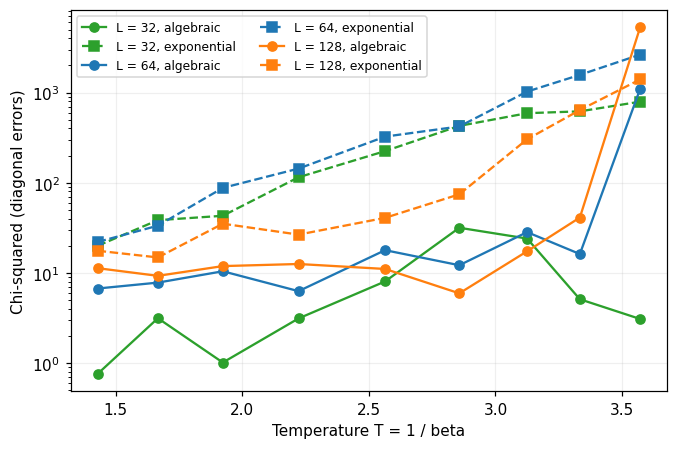

In [47]:
plt.figure()
for i, L in enumerate(sizes):
    plt.plot(T, alg_chi2[i], 'o-', color=colours[i], label=f'L = {L}, algebraic')
    plt.plot(T, exp_chi2[i], 's--', color=colours[i], label=f'L = {L}, exponential')
plt.yscale('log')

plt.xlabel('Temperature T = 1 / beta')
plt.ylabel('Chi-squared (diagonal errors)')
plt.legend(ncol=2, fontsize=8)
plt.grid(alpha=.2)
plt.show()

### Reduced chi-squared (diagonal errors) against temperature

A logarithmic vertical axis keeps the small and large values visible.

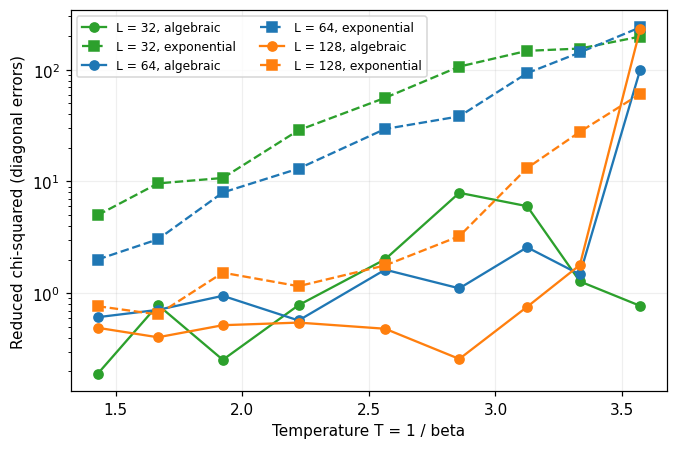

In [48]:
plt.figure()
for i, L in enumerate(sizes):
    plt.plot(T, alg_reduced[i], 'o-', color=colours[i], label=f'L = {L}, algebraic')
    plt.plot(T, exp_reduced[i], 's--', color=colours[i], label=f'L = {L}, exponential')
plt.yscale('log')

plt.xlabel('Temperature T = 1 / beta')
plt.ylabel('Reduced chi-squared (diagonal errors)')
plt.legend(ncol=2, fontsize=8)
plt.grid(alpha=.2)
plt.show()

### Nominal p-value (diagonal errors) against temperature

These probabilities assume independent distances; they are not calibrated for the correlated simulation data.

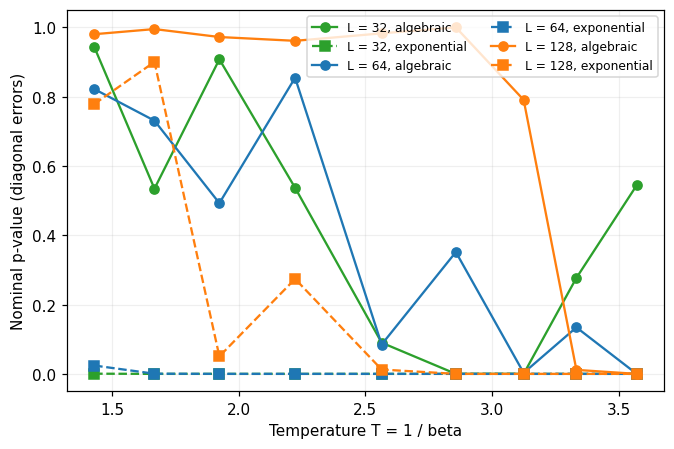

In [49]:
plt.figure()
for i, L in enumerate(sizes):
    plt.plot(T, alg_p_nominal[i], 'o-', color=colours[i], label=f'L = {L}, algebraic')
    plt.plot(T, exp_p_nominal[i], 's--', color=colours[i], label=f'L = {L}, exponential')

plt.xlabel('Temperature T = 1 / beta')
plt.ylabel('Nominal p-value (diagonal errors)')
plt.legend(ncol=2, fontsize=8)
plt.grid(alpha=.2)
plt.show()

## Squared winding numbers

Plot $\langle W_x^2\rangle$, $\langle W_y^2\rangle$ and their sum separately for all sizes and temperatures. Faint dots show each of the three productions; the line shows the count-weighted mean. The component error bars use the stored marginal errors and the production-weighting approximation above. The sum has no error bar because the covariance of the two components is not stored.

### $\langle W_x^2\rangle$

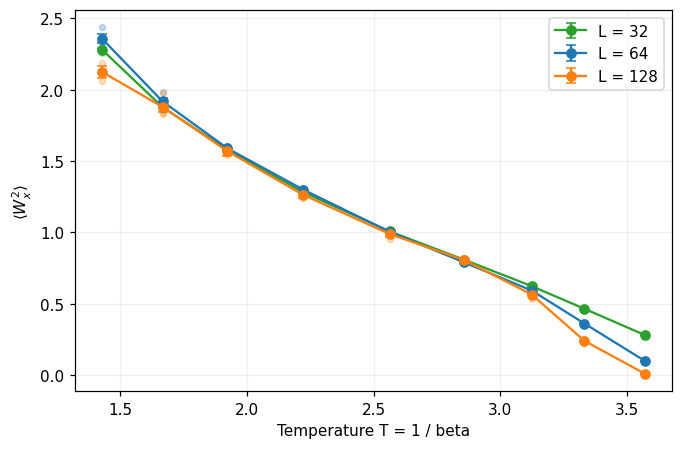

In [50]:
plt.figure()
for L, colour in zip(sizes, colours):
    mean = np.array([W[L, beta][0] for beta in betas])
    error = np.array([W_error[L, beta][0] for beta in betas])
    productions = np.array([winding_runs[L, beta][:, 0] for beta in betas])
    plt.scatter(np.repeat(T, 3), productions.ravel(), color=colour, alpha=.25, s=15)
    plt.errorbar(T, mean, yerr=error, fmt='o-', color=colour, capsize=3, label=f'L = {L}')
plt.xlabel('Temperature T = 1 / beta')
plt.ylabel(r'$\langle W_x^2\rangle$')
plt.legend()
plt.grid(alpha=.2)
plt.show()

### $\langle W_y^2\rangle$

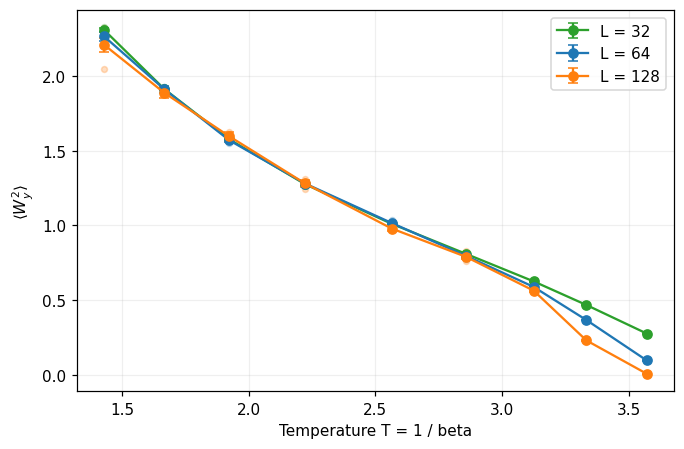

In [51]:
plt.figure()
for L, colour in zip(sizes, colours):
    mean = np.array([W[L, beta][1] for beta in betas])
    error = np.array([W_error[L, beta][1] for beta in betas])
    productions = np.array([winding_runs[L, beta][:, 1] for beta in betas])
    plt.scatter(np.repeat(T, 3), productions.ravel(), color=colour, alpha=.25, s=15)
    plt.errorbar(T, mean, yerr=error, fmt='o-', color=colour, capsize=3, label=f'L = {L}')
plt.xlabel('Temperature T = 1 / beta')
plt.ylabel(r'$\langle W_y^2\rangle$')
plt.legend()
plt.grid(alpha=.2)
plt.show()

### Total $\langle W_x^2+W_y^2\rangle$

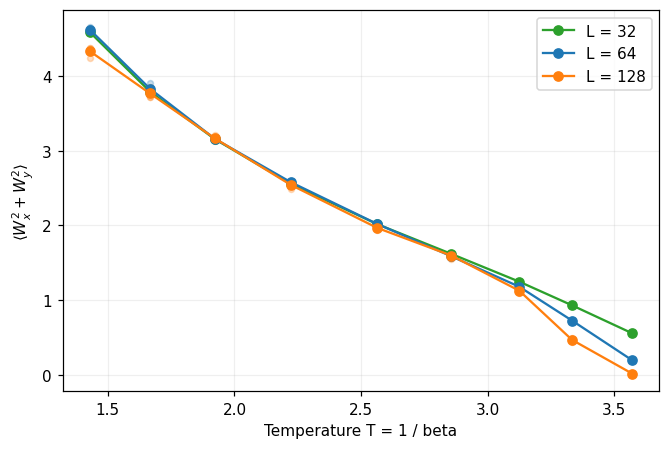

In [52]:
plt.figure()
for L, colour in zip(sizes, colours):
    mean = np.array([W[L, beta].sum() for beta in betas])
    productions = np.array([winding_runs[L, beta].sum(axis=1) for beta in betas])
    plt.scatter(np.repeat(T, 3), productions.ravel(), color=colour, alpha=.25, s=15)
    plt.plot(T, mean, 'o-', color=colour, label=f'L = {L}')
plt.xlabel('Temperature T = 1 / beta')
plt.ylabel(r'$\langle W_x^2+W_y^2\rangle$')
plt.legend()
plt.grid(alpha=.2)
plt.show()

## Save the numbers together

One row per size and temperature, containing both fits, chi-squared, reduced chi-squared, nominal p-values and the squared winding components. The input HDF5 files are unchanged. Changing the fitting interval or temperature list above and rerunning updates this table.

In [53]:
rows = []
for i, L in enumerate(sizes):
    for j, beta in enumerate(betas):
        rows.append([L, beta, 1/beta, *alg_parameters[i, j], *exp_parameters[i, j],
                     alg_chi2[i, j], exp_chi2[i, j], degrees_of_freedom[i, j],
                     alg_reduced[i, j], exp_reduced[i, j], alg_p_nominal[i, j], exp_p_nominal[i, j],
                     *W[L, beta], W[L, beta].sum(), histograms[L, beta].sum()])
output = results / 'cleanRbRDM' / 'analysis' / 'simple_density_fits_and_winding.csv'
output.parent.mkdir(parents=True, exist_ok=True)
np.savetxt(output, rows, delimiter=',', comments='',
           header='L,beta,T,A_alg,eta,A_exp,xi,chi2_alg_diag,chi2_exp_diag,dof,reduced_alg_diag,reduced_exp_diag,p_alg_nominal,p_exp_nominal,Wx2,Wy2,W2,density_histograms')
print(output)

\\alfs1.physics.ox.ac.uk\al\kuo\projects\worm\results\cleanRbRDM\analysis\simple_density_fits_and_winding.csv


SciPy references: [curve_fit and absolute_sigma](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.curve_fit.html), [chi-squared survival function](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2.html).

## Equal-time superfluid susceptibility

Following the [paper's definition](https://arxiv.org/html/1305.3032v3), the lattice observable is

$$\chi_s = \frac{1}{L^2}\sum_{ij}\langle b_i^\dagger b_j\rangle
         = \sum_{dx,dy}G(dx,dy).$$

This is the zero-momentum occupation. Sum the **whole displacement matrix**, including the corners; there is no extra factor of beta or division by $L^2$. It is different from the fit statistic $\chi^2$ above.

The saved on-site estimator is biased, so replace $G(0,0)$ by the exact density $N/L^2$ in these canonical runs:

$$\chi_s = \sum_{dx,dy}G(dx,dy)-G(0,0)+N/L^2.$$

Compute this separately for each production, then average using its histogram count. Faint dots below show the three productions; lines show their weighted mean. They are successive production blocks, not three independent runs. We omit error bars because the spatial covariance needed for the error of the sum is not stored.

In [54]:
susceptibility_runs = np.zeros((len(sizes), len(betas), 3))
susceptibility = np.zeros((len(sizes), len(betas)))
susceptibility_rows = []
susceptibility_summary = []

for i, L in enumerate(sizes):
    for j, beta in enumerate(betas):
        name = f'l{L}t{round(100 * beta):03d}'
        folder = results / 'cleanRbRDM' / name
        if not folder.is_dir():
            folder = results / 'clean_Rb87' / name
        files = sorted(folder.glob('*prod[0-9][0-9].h5'))
        assert len(files) == 3

        for p, file in enumerate(files):
            with h5py.File(file, 'r') as f:
                parameters = f['parameters']
                N = int(parameters['canonical'][()])
                assert N >= 0, 'This section uses the exact particle number of canonical runs.'
                assert int(parameters['Lx'][()]) == L and int(parameters['Ly'][()]) == L
                assert np.isclose(float(parameters['beta'][()]), beta)
                assert int(f['simulation/results/Density_Matrix/count'][()]) == histograms[L, beta][p]

            matrix = density_runs[L, beta][p]
            density = N / L**2
            susceptibility_runs[i, j, p] = matrix.sum() - matrix[0, 0] + density
            susceptibility_rows.append([
                L, beta, 1 / beta, p + 1, str(file.relative_to(results)),
                N, density, int(histograms[L, beta][p]), matrix[0, 0], matrix.sum(),
                susceptibility_runs[i, j, p], susceptibility_runs[i, j, p] / L**1.75])

        susceptibility[i, j] = np.average(susceptibility_runs[i, j],
                                         weights=histograms[L, beta])
        susceptibility_summary.append([
            L, beta, 1 / beta, density, int(histograms[L, beta].sum()),
            susceptibility[i, j], susceptibility[i, j] / L**1.75])

print('Histogram-weighted susceptibility, with G(0,0) replaced by N / L**2')
print('  T        L = 32       L = 64      L = 128')
for j, temperature in enumerate(T):
    print(f'{temperature:6.3f}  ' + '  '.join(f'{value:11.3f}' for value in susceptibility[:, j]))

Histogram-weighted susceptibility, with G(0,0) replaced by N / L**2
  T        L = 32       L = 64      L = 128
 1.429     1529.629     5839.773    22194.149
 1.667     1456.065     5500.627    20390.769
 1.923     1363.226     5071.902    18620.462
 2.222     1250.607     4562.394    16611.304
 2.564     1112.695     3972.056    14483.577
 2.857      976.678     3374.239    11812.243
 3.125      838.191     2733.968     8681.607
 3.333      704.413     2022.482     5196.261
 3.571      522.098     1015.834     1240.816


### Susceptibility against temperature

Use the same temperature convention as the plots above: $T=1/\beta$ in hopping units. These are unnormalized occupations, not condensate fractions.

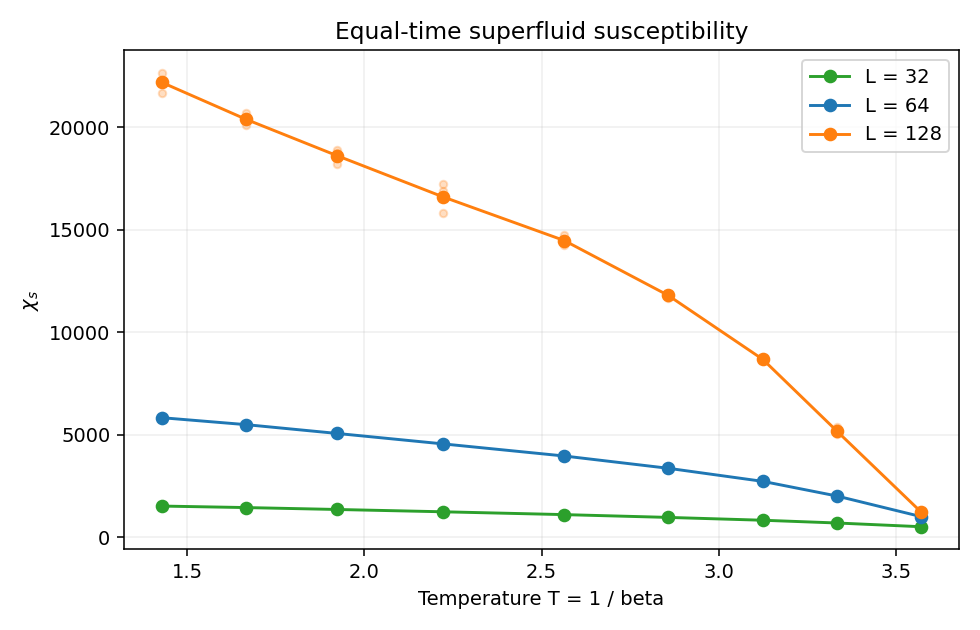

In [55]:
plt.figure()
for i, L in enumerate(sizes):
    plt.scatter(np.repeat(T, 3), susceptibility_runs[i].ravel(),
                color=colours[i], alpha=.25, s=15)
    plt.plot(T, susceptibility[i], 'o-', color=colours[i], label=f'L = {L}')
plt.xlabel('Temperature T = 1 / beta')
plt.ylabel(r'$\chi_s$')
plt.title('Equal-time superfluid susceptibility')
plt.legend()
plt.grid(alpha=.2)
plt.tight_layout()
plt.show()

### BKT scaling: $\chi_s/L^{7/4}$ against temperature

The paper uses approximately crossing curves of this quantity to study the transition. This is a leading-power diagnostic: logarithmic finite-size corrections cause drift, so a crossing alone does not give a precision transition temperature. The current clean-system data also require statistical and occupation-cutoff convergence checks (`nmax = 5`).

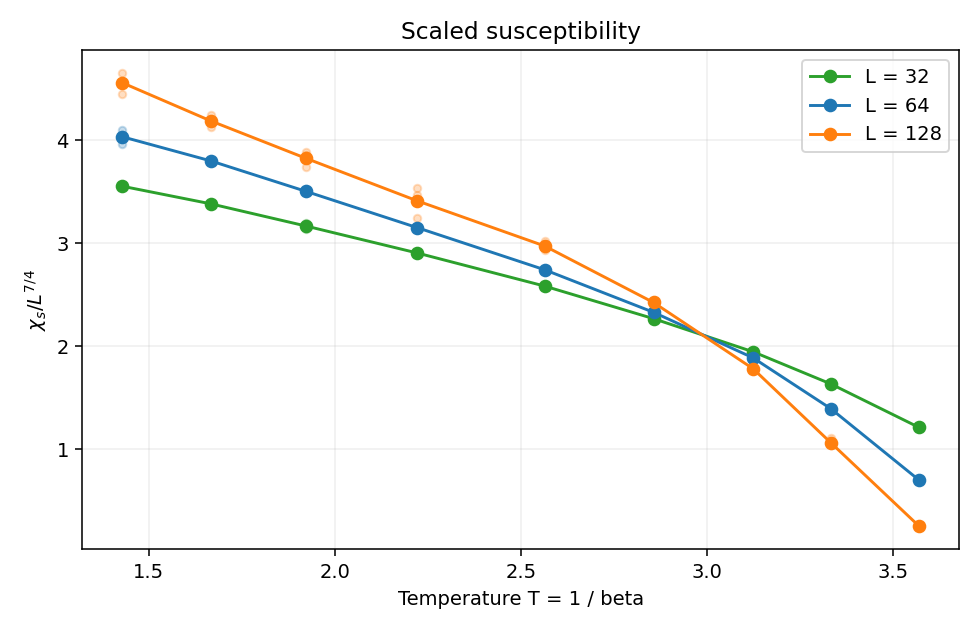

In [56]:
plt.figure()
for i, L in enumerate(sizes):
    plt.scatter(np.repeat(T, 3), susceptibility_runs[i].ravel() / L**1.75,
                color=colours[i], alpha=.25, s=15)
    plt.plot(T, susceptibility[i] / L**1.75, 'o-',
             color=colours[i], label=f'L = {L}')
plt.xlabel('Temperature T = 1 / beta')
plt.ylabel(r'$\chi_s/L^{7/4}$')
plt.title('Scaled susceptibility')
plt.legend()
plt.grid(alpha=.2)
plt.tight_layout()
plt.show()

### Susceptibility against system size

Compare all temperatures on logarithmic axes. The dashed line has slope $7/4$, with an arbitrary amplitude anchored to the L = 32 point nearest beta = 0.35. It is a visual guide, not a fit.

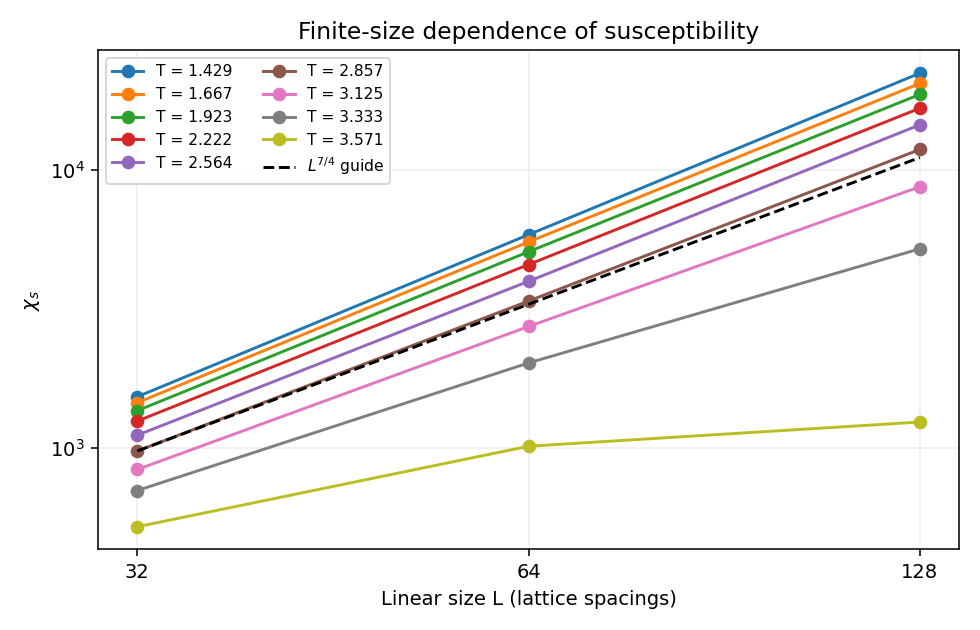

In [57]:
plt.figure()
for j, beta in enumerate(betas):
    plt.loglog(sizes, susceptibility[:, j], 'o-', label=f'T = {1 / beta:.3f}')
reference = np.argmin(np.abs(np.array(betas) - .35))
size_guide = np.array(sizes, dtype=float)
plt.loglog(size_guide, susceptibility[0, reference] * (size_guide / sizes[0])**1.75,
           'k--', linewidth=1.5, label=r'$L^{7/4}$ guide')
plt.xticks(sizes, sizes)
plt.minorticks_off()
plt.xlabel('Linear size L (lattice spacings)')
plt.ylabel(r'$\chi_s$')
plt.title('Finite-size dependence of susceptibility')
plt.legend(ncol=2, fontsize=8)
plt.grid(alpha=.2, which='both')
plt.tight_layout()
plt.show()

### Save the susceptibility values

Save both the 27 weighted means and the 81 individual productions. The production table records each source file, histogram count, measured on-site entry and correction. No uncertainty is assigned from the marginal spatial errors.

In [58]:
import csv

susceptibility_output = results / 'cleanRbRDM' / 'analysis'
susceptibility_output.mkdir(parents=True, exist_ok=True)
with (susceptibility_output / 'susceptibility_summary.csv').open('w', newline='') as stream:
    writer = csv.writer(stream)
    writer.writerow(['L', 'beta', 'T', 'density', 'density_histograms',
                     'chi_s', 'chi_s_over_L_7over4'])
    writer.writerows(susceptibility_summary)
with (susceptibility_output / 'susceptibility_productions.csv').open('w', newline='') as stream:
    writer = csv.writer(stream)
    writer.writerow(['L', 'beta', 'T', 'production', 'source_file', 'N', 'density',
                     'density_histograms', 'G0_raw', 'chi_s_raw', 'chi_s', 'chi_s_over_L_7over4'])
    writer.writerows(susceptibility_rows)
print(susceptibility_output / 'susceptibility_summary.csv')
print(susceptibility_output / 'susceptibility_productions.csv')

\\alfs1.physics.ox.ac.uk\al\kuo\projects\worm\results\cleanRbRDM\analysis\susceptibility_summary.csv
\\alfs1.physics.ox.ac.uk\al\kuo\projects\worm\results\cleanRbRDM\analysis\susceptibility_productions.csv
